In [23]:
# Cell 1：导入库与参数设置

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, accuracy_score, confusion_matrix
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance

plt.rcParams["font.sans-serif"] = ["SimHei", "Microsoft YaHei", "Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False

# 输出文件夹
OUT_DIR = Path("BP神经网络水质综合评价输出结果")
OUT_DIR.mkdir(exist_ok=True)

# 随机种子，保证结果可复现
RANDOM_STATE = 42

# 每类生成 200 组标准样本，6 类共 1200 组
N_PER_CLASS = 500

# 本文选取的 5 个评价指标
FEATURES = ["pH", "溶解氧", "高锰酸盐指数", "氨氮", "总磷"]

# 水质类别名称
CLASS_NAMES = {
    1: "Ⅰ类",
    2: "Ⅱ类",
    3: "Ⅲ类",
    4: "Ⅳ类",
    5: "Ⅴ类",
    6: "劣Ⅴ类"
}

CLASS_ORDER = [CLASS_NAMES[i] for i in range(1, 7)]

print("库导入和参数设置完成")

库导入和参数设置完成


In [24]:
# Cell 2：读取实测水质数据

RAW_PATH = "水质数据.csv"  # 修改成你的实际文件名，例如 "水质数据.xlsx"


def read_table(path):
    path = Path(path)

    if path.suffix.lower() in [".xlsx", ".xls"]:
        return pd.read_excel(path)

    encodings = ["utf-8-sig", "gb18030", "gbk", "utf-8"]

    for enc in encodings:
        try:
            return pd.read_csv(path, encoding=enc)
        except UnicodeDecodeError:
            continue

    return pd.read_csv(path)


df_raw = read_table(RAW_PATH)

print("原始数据规模：", df_raw.shape)
display(df_raw.head())

print("原始字段：")
print(list(df_raw.columns))

原始数据规模： (707, 23)


,省份,城市,河流,流域,断面名称,监测时间,水质类别,水温,pH,pH类别,...,高锰酸盐类别,氨氮,氨氮类别,总磷,总氮,电导率,浊度,叶绿素,藻密度,站点情况
0,江苏省,南京市,NaN,长江流域,七桥瓮,2026/6/1 1:00,4,27.17,7.239,-,...,-,0.6883,-,0.1387,2.705,499.42,29.32,NaN,NaN,NaN
1,江苏省,南京市,NaN,长江流域,节制闸,2026/6/1 1:00,2,24.80,8.000,-,...,-,0.1003,-,0.0806,2.050,357.86,21.55,NaN,NaN,NaN
2,江苏省,南京市,NaN,长江流域,钱家渡,2026/6/1 1:00,2,26.60,7.840,-,...,-,NaN,-,0.0350,1.185,341.43,26.24,NaN,NaN,NaN
3,江苏省,南京市,NaN,长江流域,陈浅,2026/6/1 1:00,4,26.49,7.144,-,...,-,0.1133,-,0.0997,1.765,563.64,24.22,NaN,NaN,NaN
4,江苏省,南京市,NaN,长江流域,七桥瓮,2026/6/1 2:00,4,26.99,7.223,-,...,-,0.6883,-,0.1387,2.705,491.33,31.48,NaN,NaN,NaN


原始字段：
['省份', '城市', '河流', '流域', '断面名称', '监测时间', '水质类别', '水温', 'pH', 'pH类别', '溶解氧', '溶解氧类别', '高锰酸盐指数', '高锰酸盐类别', '氨氮', '氨氮类别', '总磷', '总氮', '电导率', '浊度', '叶绿素', '藻密度', '站点情况']


In [25]:
# Cell 3：初始处理与指标检查

df = df_raw.copy()

# 检查是否缺少必要指标
missing_features = [col for col in FEATURES if col not in df.columns]

if missing_features:
    raise ValueError(f"数据中缺少以下指标列：{missing_features}，请检查表头是否一致。")

# 将指标转为数值型，防止存在字符串、空格等问题
for col in FEATURES:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("各指标缺失值数量：")
display(df[FEATURES].isna().sum())

print("初始处理后的数据：")
display(df[FEATURES].head())

各指标缺失值数量：


pH          0
溶解氧         2
高锰酸盐指数     52
氨氮        172
总磷          0
dtype: int64

初始处理后的数据：


,pH,溶解氧,高锰酸盐指数,氨氮,总磷
0,7.239,3.468,4.532,0.6883,0.1387
1,8.000,9.320,2.899,0.1003,0.0806
2,7.840,7.860,3.061,NaN,0.0350
3,7.144,3.714,7.484,0.1133,0.0997
4,7.223,3.543,4.532,0.6883,0.1387


In [26]:
# Cell 4：设置国标限值与单因子评价函数

# 越低越好的指标：高锰酸盐指数、氨氮、总磷
# 依次对应Ⅰ、Ⅱ、Ⅲ、Ⅳ、Ⅴ类标准限值
LIMITS_LOW = {
    "高锰酸盐指数": [2, 4, 6, 10, 15],
    "氨氮": [0.15, 0.5, 1.0, 1.5, 2.0],
    "总磷": [0.02, 0.1, 0.2, 0.3, 0.4]
}

# 越高越好的指标：溶解氧
LIMITS_HIGH = {
    "溶解氧": [7.5, 6, 5, 3, 2]
}


def grade_lower_better(x, limits):
    """
    越低越好的指标：
    数值越小，水质越好。
    超过Ⅴ类标准，记为劣Ⅴ类。
    """
    if pd.isna(x):
        return np.nan

    for i, limit in enumerate(limits, start=1):
        if x <= limit:
            return i

    return 6


def grade_higher_better(x, limits):
    """
    越高越好的指标：
    数值越大，水质越好。
    低于Ⅴ类标准，记为劣Ⅴ类。
    """
    if pd.isna(x):
        return np.nan

    for i, limit in enumerate(limits, start=1):
        if x >= limit:
            return i

    return 6


def grade_ph(x):
    """
    pH 指标：
    Ⅰ—Ⅴ类通常要求在 6~9 范围内。
    在 6~9 内视为达标，超出范围记为劣Ⅴ类。
    """
    if pd.isna(x):
        return np.nan

    if 6 <= x <= 9:
        return 1
    else:
        return 6


def evaluate_single_factor(row, features):
    """
    单因子评价法：
    对每个指标分别判定类别，最终水质类别取最差指标类别。
    """
    detail = {}

    for col in features:
        value = row[col]

        if col == "pH":
            g = grade_ph(value)
        elif col in LIMITS_HIGH:
            g = grade_higher_better(value, LIMITS_HIGH[col])
        elif col in LIMITS_LOW:
            g = grade_lower_better(value, LIMITS_LOW[col])
        else:
            continue

        if not pd.isna(g):
            detail[col] = int(g)

    if len(detail) == 0:
        return pd.Series([np.nan, np.nan, "", ""])

    overall_grade = max(detail.values())
    overall_class = CLASS_NAMES[overall_grade]

    main_factors = "、".join([k for k, v in detail.items() if v == overall_grade])
    detail_text = "；".join([f"{k}:{CLASS_NAMES[v]}" for k, v in detail.items()])

    return pd.Series([overall_grade, overall_class, main_factors, detail_text])


print("国标限值与单因子评价函数设置完成")

国标限值与单因子评价函数设置完成


In [27]:
# Cell 5：单因子评价实测样本

result = df.copy()

result[["单因子类别编号", "单因子水质类别", "主要限制指标", "各指标类别"]] = result.apply(
    lambda row: evaluate_single_factor(row, FEATURES),
    axis=1
)

display(result[FEATURES + ["单因子水质类别", "主要限制指标", "各指标类别"]].head())

print("单因子评价类别分布：")
display(result["单因子水质类别"].value_counts().reindex(CLASS_ORDER, fill_value=0))

,pH,溶解氧,高锰酸盐指数,氨氮,总磷,单因子水质类别,主要限制指标,各指标类别
0,7.239,3.468,4.532,0.6883,0.1387,Ⅳ类,溶解氧,pH:Ⅰ类；溶解氧:Ⅳ类；高锰酸盐指数:Ⅲ类；氨氮:Ⅲ类；总磷:Ⅲ类
1,8.000,9.320,2.899,0.1003,0.0806,Ⅱ类,高锰酸盐指数、总磷,pH:Ⅰ类；溶解氧:Ⅰ类；高锰酸盐指数:Ⅱ类；氨氮:Ⅰ类；总磷:Ⅱ类
2,7.840,7.860,3.061,NaN,0.0350,Ⅱ类,高锰酸盐指数、总磷,pH:Ⅰ类；溶解氧:Ⅰ类；高锰酸盐指数:Ⅱ类；总磷:Ⅱ类
3,7.144,3.714,7.484,0.1133,0.0997,Ⅳ类,溶解氧、高锰酸盐指数,pH:Ⅰ类；溶解氧:Ⅳ类；高锰酸盐指数:Ⅳ类；氨氮:Ⅰ类；总磷:Ⅱ类
4,7.223,3.543,4.532,0.6883,0.1387,Ⅳ类,溶解氧,pH:Ⅰ类；溶解氧:Ⅳ类；高锰酸盐指数:Ⅲ类；氨氮:Ⅲ类；总磷:Ⅲ类


单因子评价类别分布：


单因子水质类别
Ⅰ类       0
Ⅱ类     314
Ⅲ类      71
Ⅳ类     195
Ⅴ类      56
劣Ⅴ类     71
Name: count, dtype: int64

In [28]:
# Cell 6：根据国标六类生成标准训练样本

def interval_lower_better(limits, grade):
    """
    越低越好指标的等级区间。
    grade=1~5 对应Ⅰ~Ⅴ类；
    grade=6 表示劣Ⅴ类，即超过Ⅴ类标准。
    """
    if grade == 1:
        return 0.0001, limits[0]

    elif grade in [2, 3, 4, 5]:
        return limits[grade - 2], limits[grade - 1]

    else:
        # 劣Ⅴ类：超过Ⅴ类标准，不再严格设置真实上限
        return limits[-1], limits[-1] * 2.0 + 0.0001


def sample_value_by_grade(rng, feature, grade):
    """
    根据指标和类别随机生成标准样本值。
    """

    # pH：Ⅰ—Ⅴ类在 6~9 内，劣Ⅴ类超出 6~9
    if feature == "pH":
        if grade <= 5:
            return rng.uniform(6.0, 9.0)
        else:
            if rng.random() < 0.5:
                return rng.uniform(4.5, 6.0)
            else:
                return rng.uniform(9.0, 10.5)

    # 溶解氧：越高越好
    elif feature == "溶解氧":
        intervals = {
            1: (7.5, 12.0),
            2: (6.0, 7.5),
            3: (5.0, 6.0),
            4: (3.0, 5.0),
            5: (2.0, 3.0),
            6: (0.1, 2.0)
        }
        lo, hi = intervals[grade]
        return rng.uniform(lo, hi)

    # 其他污染物指标：越低越好
    elif feature in LIMITS_LOW:
        lo, hi = interval_lower_better(LIMITS_LOW[feature], grade)
        return rng.uniform(lo, hi)

    else:
        raise ValueError(f"暂不支持该指标：{feature}")


def generate_standard_samples(features, n_per_class=200, random_state=42):
    """
    根据国标六类生成标准训练样本。
    每类生成 n_per_class 组，六类共 6*n_per_class 组。
    """

    rng = np.random.default_rng(random_state)

    rows = []
    y = []

    for grade in range(1, 7):

        for _ in range(n_per_class):

            record = {}

            # 每条样本至少强制一个指标达到当前类别，
            # 其余指标可以优于或等于当前类别。
            if grade < 6:
                candidate_forced_features = [f for f in features if f != "pH"]
            else:
                candidate_forced_features = features.copy()

            forced_feature = rng.choice(candidate_forced_features)

            for feature in features:

                if feature == forced_feature:
                    g = grade
                else:
                    if grade == 1:
                        g = 1
                    else:
                        g = int(rng.integers(1, grade + 1))

                    # 对Ⅰ—Ⅴ类样本，pH 保持在正常范围
                    if feature == "pH" and grade < 6:
                        g = 1

                record[feature] = sample_value_by_grade(rng, feature, g)

            rows.append(record)
            y.append(float(grade))

    X_standard = pd.DataFrame(rows)
    y_standard = np.array(y)

    return X_standard, y_standard


X_standard, y_standard = generate_standard_samples(
    FEATURES,
    n_per_class=N_PER_CLASS,
    random_state=RANDOM_STATE
)

standard_df = X_standard.copy()
standard_df["类别编号"] = y_standard.astype(int)
standard_df["水质类别"] = standard_df["类别编号"].map(CLASS_NAMES)

print("标准样本规模：", standard_df.shape)
display(standard_df.head())

print("各类别标准样本数量：")
display(standard_df["水质类别"].value_counts().reindex(CLASS_ORDER, fill_value=0))

标准样本规模： (3000, 7)


,pH,溶解氧,高锰酸盐指数,氨氮,总磷,类别编号,水质类别
0,7.316635,11.363691,1.394766,0.014217,0.019515,1,Ⅰ类
1,8.283419,11.037289,0.256314,0.067613,0.007479,1,Ⅰ类
2,7.931595,11.202427,0.886884,0.034163,0.011136,1,Ⅰ类
3,6.191452,11.224340,1.263366,0.113737,0.007155,1,Ⅰ类
4,8.679363,11.002726,0.389358,0.070061,0.000972,1,Ⅰ类


各类别标准样本数量：


水质类别
Ⅰ类     500
Ⅱ类     500
Ⅲ类     500
Ⅳ类     500
Ⅴ类     500
劣Ⅴ类    500
Name: count, dtype: int64

In [29]:
# Cell 7：划分 BP 训练集和验证集

X_train, X_val, y_train, y_val = train_test_split(
    X_standard,
    y_standard,
    test_size=300,
    random_state=RANDOM_STATE,
    stratify=y_standard
)

print("训练集规模：", X_train.shape)
print("验证集规模：", X_val.shape)

print("训练集类别分布：")
display(pd.Series(y_train).astype(int).map(CLASS_NAMES).value_counts().reindex(CLASS_ORDER, fill_value=0))

print("验证集类别分布：")
display(pd.Series(y_val).astype(int).map(CLASS_NAMES).value_counts().reindex(CLASS_ORDER, fill_value=0))

训练集规模： (2700, 5)
验证集规模： (300, 5)
训练集类别分布：


Ⅰ类     450
Ⅱ类     450
Ⅲ类     450
Ⅳ类     450
Ⅴ类     450
劣Ⅴ类    450
Name: count, dtype: int64

验证集类别分布：


Ⅰ类     50
Ⅱ类     50
Ⅲ类     50
Ⅳ类     50
Ⅴ类     50
劣Ⅴ类    50
Name: count, dtype: int64

In [34]:
# Cell 8：归一化并训练 BP 神经网络连续评价模型

bp_model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler(feature_range=(-1, 1))),
    ("bp", MLPRegressor(
        hidden_layer_sizes=(14,),
        activation="logistic",
        solver="adam",
        alpha=0.0005,
        learning_rate_init=0.003,
        max_iter=5000,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=80,
        random_state=RANDOM_STATE
    ))
])

bp_model.fit(X_train, y_train)

print("BP 神经网络连续评价模型训练完成")

BP 神经网络连续评价模型训练完成


In [35]:
# Cell 9：不同隐藏层节点数对模型准确率的影响

def continuous_to_grade(values):
    """
    将 BP 连续输出值转换为类别编号。
    采用默认中点分界：
    1.5 以下为Ⅰ类，1.5~2.5 为Ⅱ类，依此类推。
    """
    values = np.clip(values, 1, 6)
    grades = np.rint(values).astype(int)
    grades = np.clip(grades, 1, 6)
    return grades


hidden_results = []
hidden_models = {}

candidate_hidden_nodes = list(range(4, 15))

for nodes in candidate_hidden_nodes:

    model = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", MinMaxScaler(feature_range=(-1, 1))),
        ("bp", MLPRegressor(
            hidden_layer_sizes=(nodes,),
            activation="logistic",
            solver="adam",
            alpha=0.0005,
            learning_rate_init=0.003,
            max_iter=5000,
            early_stopping=True,
            validation_fraction=0.15,
            n_iter_no_change=80,
            random_state=RANDOM_STATE
        ))
    ])

    model.fit(X_train, y_train)

    val_pred_cont = model.predict(X_val)
    val_pred_cont = np.clip(val_pred_cont, 1, 6)

    val_pred_grade = continuous_to_grade(val_pred_cont)
    y_val_grade = y_val.astype(int)

    rmse = np.sqrt(mean_squared_error(y_val, val_pred_cont))
    mae = mean_absolute_error(y_val, val_pred_cont)
    r2 = r2_score(y_val, val_pred_cont)
    acc = accuracy_score(y_val_grade, val_pred_grade)

    hidden_results.append({
        "隐藏层节点数": nodes,
        "验证集RMSE": rmse,
        "验证集MAE": mae,
        "验证集R2": r2,
        "验证集准确率": acc
    })

    hidden_models[nodes] = model


hidden_result_df = pd.DataFrame(hidden_results)

display(hidden_result_df)

best_row = hidden_result_df.sort_values(
    by=["验证集准确率", "验证集RMSE"],
    ascending=[False, True]
).iloc[0]

best_hidden_nodes = int(best_row["隐藏层节点数"])
best_model = hidden_models[best_hidden_nodes]

print("最优隐藏层节点数：", best_hidden_nodes)
print("最高验证集准确率：", round(best_row["验证集准确率"] * 100, 2), "%")
print("对应 RMSE：", round(best_row["验证集RMSE"], 4))

,隐藏层节点数,验证集RMSE,验证集MAE,验证集R2,验证集准确率
0,4,0.533331,0.354689,0.902477,0.733333
1,5,0.527123,0.363198,0.904734,0.770000
2,6,0.502790,0.345356,0.913326,0.736667
3,7,0.534441,0.355719,0.902071,0.746667
4,8,0.523986,0.349090,0.905865,0.746667
5,9,0.480792,0.326727,0.920745,0.783333
6,10,0.476712,0.329646,0.922084,0.780000
7,11,0.442481,0.311071,0.932872,0.766667
8,12,0.413023,0.279999,0.941513,0.816667
9,13,0.396271,0.257580,0.946161,0.870000


最优隐藏层节点数： 14
最高验证集准确率： 87.67 %
对应 RMSE： 0.3833


In [36]:
# Cell 10：输出最优 BP 模型验证效果

val_pred_cont = best_model.predict(X_val)
val_pred_cont = np.clip(val_pred_cont, 1, 6)

val_pred_grade = continuous_to_grade(val_pred_cont)
y_val_grade = y_val.astype(int)

val_rmse = np.sqrt(mean_squared_error(y_val, val_pred_cont))
val_mae = mean_absolute_error(y_val, val_pred_cont)
val_r2 = r2_score(y_val, val_pred_cont)
val_acc = accuracy_score(y_val_grade, val_pred_grade)

print("最优 BP 网络结构：", f"5-{best_hidden_nodes}-1")
print("验证集 RMSE：", round(val_rmse, 4))
print("验证集 MAE：", round(val_mae, 4))
print("验证集 R²：", round(val_r2, 4))
print("验证集分类准确率：", round(val_acc * 100, 2), "%")

cm = confusion_matrix(y_val_grade, val_pred_grade, labels=[1, 2, 3, 4, 5, 6])

cm_df = pd.DataFrame(
    cm,
    index=[f"真实{c}" for c in CLASS_ORDER],
    columns=[f"预测{c}" for c in CLASS_ORDER]
)

display(cm_df)

最优 BP 网络结构： 5-14-1
验证集 RMSE： 0.3833
验证集 MAE： 0.2439
验证集 R²： 0.9496
验证集分类准确率： 87.67 %


,预测Ⅰ类,预测Ⅱ类,预测Ⅲ类,预测Ⅳ类,预测Ⅴ类,预测劣Ⅴ类
真实Ⅰ类,50,0,0,0,0,0
真实Ⅱ类,0,47,3,0,0,0
真实Ⅲ类,0,3,44,3,0,0
真实Ⅳ类,0,0,5,33,12,0
真实Ⅴ类,0,0,0,5,45,0
真实劣Ⅴ类,0,1,0,0,5,44


In [37]:
# Cell 11：建立 BP 连续输出分界值

def make_boundary_samples(features):
    """
    构造Ⅰ/Ⅱ、Ⅱ/Ⅲ、Ⅲ/Ⅳ、Ⅳ/Ⅴ、Ⅴ/劣Ⅴ边界样本。
    """
    rows = []

    for k in range(1, 6):

        record = {}

        for feature in features:

            if feature == "pH":
                record[feature] = 7.5

            elif feature == "溶解氧":
                record[feature] = LIMITS_HIGH["溶解氧"][k - 1]

            elif feature in LIMITS_LOW:
                record[feature] = LIMITS_LOW[feature][k - 1]

            else:
                raise ValueError(f"暂不支持该指标：{feature}")

        rows.append(record)

    return pd.DataFrame(rows)


boundary_samples = make_boundary_samples(FEATURES)

raw_bp_boundaries = best_model.predict(boundary_samples)
raw_bp_boundaries = np.clip(raw_bp_boundaries, 1, 6)

default_boundaries = np.array([1.5, 2.5, 3.5, 4.5, 5.5])

# 如果模型边界输出单调递增，就采用模型边界；否则采用默认中点
if np.all(np.diff(raw_bp_boundaries) > 0):
    bp_boundaries = raw_bp_boundaries
    boundary_source = "BP模型边界样本输出值"
else:
    bp_boundaries = default_boundaries
    boundary_source = "默认中点分界值"


bp_boundary_table = pd.DataFrame({
    "分界": ["Ⅰ/Ⅱ", "Ⅱ/Ⅲ", "Ⅲ/Ⅳ", "Ⅳ/Ⅴ", "Ⅴ/劣Ⅴ"],
    "BP原始分界输出": raw_bp_boundaries,
    "最终采用分界值": bp_boundaries
})

print("BP分界值来源：", boundary_source)
display(bp_boundary_table)


def score_to_grade(score, boundaries):
    """
    将连续评价值转换成水质类别编号。
    """
    if pd.isna(score):
        return np.nan

    grade = np.searchsorted(boundaries, score, side="left") + 1
    grade = max(1, min(6, int(grade)))

    return grade

BP分界值来源： BP模型边界样本输出值


,分界,BP原始分界输出,最终采用分界值
0,Ⅰ/Ⅱ,1.552938,1.552938
1,Ⅱ/Ⅲ,2.644867,2.644867
2,Ⅲ/Ⅳ,3.727743,3.727743
3,Ⅳ/Ⅴ,4.986193,4.986193
4,Ⅴ/劣Ⅴ,5.669681,5.669681


In [38]:
# Cell 12：真实样本 BP 神经网络评价

X_real = result[FEATURES].copy()

bp_real_output = best_model.predict(X_real)
bp_real_output = np.clip(bp_real_output, 1, 6)

result["BP连续输出"] = bp_real_output
result["BP类别编号"] = [score_to_grade(v, bp_boundaries) for v in bp_real_output]
result["BP水质类别"] = result["BP类别编号"].map(CLASS_NAMES)

display(result[FEATURES + ["BP连续输出", "BP水质类别"]].head())

print("BP神经网络评价类别分布：")
display(result["BP水质类别"].value_counts().reindex(CLASS_ORDER, fill_value=0))

,pH,溶解氧,高锰酸盐指数,氨氮,总磷,BP连续输出,BP水质类别
0,7.239,3.468,4.532,0.6883,0.1387,3.851215,Ⅳ类
1,8.000,9.320,2.899,0.1003,0.0806,2.016635,Ⅱ类
2,7.840,7.860,3.061,NaN,0.0350,2.026713,Ⅱ类
3,7.144,3.714,7.484,0.1133,0.0997,4.198221,Ⅳ类
4,7.223,3.543,4.532,0.6883,0.1387,3.806969,Ⅳ类


BP神经网络评价类别分布：


BP水质类别
Ⅰ类      42
Ⅱ类     306
Ⅲ类     126
Ⅳ类     155
Ⅴ类      55
劣Ⅴ类     23
Name: count, dtype: int64

In [44]:
# Cell 13：PCA 综合评价（不补全缺失值版）

def make_pca_input(data, features):
    """
    PCA输入处理：
    1. pH 转换为偏离中性水平 7.5 的程度，偏离越大表示越差；
    2. 溶解氧越高越好，取负值后转为越大越差；
    3. 高锰酸盐指数、氨氮、总磷越大越差，保持原方向。
    """
    X = data[features].copy()

    if "pH" in X.columns:
        X["pH"] = (X["pH"] - 7.5).abs()

    if "溶解氧" in X.columns:
        X["溶解氧"] = -X["溶解氧"]

    return X


X_pca_standard_raw = make_pca_input(standard_df, FEATURES)
X_pca_real_raw = make_pca_input(result, FEATURES)

# =========================
# 不补全缺失值：只保留完整样本
# =========================

standard_valid_mask = X_pca_standard_raw.notna().all(axis=1)
real_valid_mask = X_pca_real_raw.notna().all(axis=1)

X_standard_valid = X_pca_standard_raw.loc[standard_valid_mask].copy()
X_real_valid = X_pca_real_raw.loc[real_valid_mask].copy()

# y_standard 也要同步筛选，保证和标准样本对应
y_standard_series = pd.Series(np.asarray(y_standard), index=X_pca_standard_raw.index)
y_standard_valid = y_standard_series.loc[standard_valid_mask].values

print("标准样本原始数量：", len(X_pca_standard_raw))
print("标准样本有效数量：", len(X_standard_valid))
print("真实样本原始数量：", len(X_pca_real_raw))
print("真实样本有效数量：", len(X_real_valid))
print("真实样本因缺失值未参与PCA数量：", len(X_pca_real_raw) - len(X_real_valid))

# 如果标准样本缺失导致某些类别没有样本，则无法计算类别中心
valid_classes = set(y_standard_valid.astype(int))
required_classes = set(range(1, 7))

if valid_classes != required_classes:
    missing_classes = required_classes - valid_classes
    raise ValueError(f"标准样本中以下类别缺失，无法计算PCA类别中心：{missing_classes}")

# 标准样本和真实样本一起标准化，保证尺度一致
pca_scaler = StandardScaler()

X_all_raw = pd.concat([X_standard_valid, X_real_valid], axis=0)
X_all_scaled = pca_scaler.fit_transform(X_all_raw)

X_standard_scaled = X_all_scaled[:len(X_standard_valid)]
X_real_scaled = X_all_scaled[len(X_standard_valid):]

# =========================
# PCA提取主成分
# =========================

pca_model = PCA()
pca_model.fit(X_standard_scaled)

explained = pca_model.explained_variance_ratio_
cum_explained = np.cumsum(explained)

pca_info = pd.DataFrame({
    "主成分": [f"PC{i+1}" for i in range(len(explained))],
    "贡献率": explained,
    "累计贡献率": cum_explained
})

display(pca_info)

# 选择累计贡献率达到 85% 的主成分
n_components = np.argmax(cum_explained >= 0.85) + 1

print("选择主成分个数：", n_components)
print("累计贡献率：", round(cum_explained[n_components - 1], 4))

# =========================
# 计算 PCA 综合得分
# =========================

Z_standard = pca_model.transform(X_standard_scaled)[:, :n_components]
Z_real = pca_model.transform(X_real_scaled)[:, :n_components]

weights = explained[:n_components] / explained[:n_components].sum()

standard_scores = Z_standard @ weights
real_scores = Z_real @ weights

# 保证得分越大，水质越差
corr_direction = np.corrcoef(standard_scores, y_standard_valid.astype(float))[0, 1]

if corr_direction < 0:
    standard_scores = -standard_scores
    real_scores = -real_scores

standard_score_df = pd.DataFrame({
    "类别编号": y_standard_valid.astype(int),
    "水质类别": [CLASS_NAMES[int(i)] for i in y_standard_valid],
    "PCA综合得分": standard_scores
})

# 每类标准样本得分中位数作为类别中心
pca_class_centers = (
    standard_score_df
    .groupby("类别编号")["PCA综合得分"]
    .median()
    .sort_index()
)

# 相邻类别中心中点作为类别分界
pca_boundaries = []

for i in range(1, 6):
    b = (pca_class_centers.loc[i] + pca_class_centers.loc[i + 1]) / 2
    pca_boundaries.append(b)

pca_boundaries = np.array(pca_boundaries)

pca_boundary_table = pd.DataFrame({
    "分界": ["Ⅰ/Ⅱ", "Ⅱ/Ⅲ", "Ⅲ/Ⅳ", "Ⅳ/Ⅴ", "Ⅴ/劣Ⅴ"],
    "PCA分界值": pca_boundaries
})

display(pca_class_centers.rename("各类别PCA得分中心"))
display(pca_boundary_table)

# =========================
# 写回 result
# 有缺失值的真实样本不参与PCA，结果保留为空
# =========================

result["PCA综合得分"] = np.nan
result["PCA类别编号"] = pd.NA
result["PCA水质类别"] = pd.NA

real_grades = pd.Series(
    [score_to_grade(s, pca_boundaries) for s in real_scores],
    index=X_real_valid.index
)

result.loc[X_real_valid.index, "PCA综合得分"] = real_scores
result.loc[X_real_valid.index, "PCA类别编号"] = real_grades
result.loc[X_real_valid.index, "PCA水质类别"] = real_grades.map(CLASS_NAMES)

display(result[FEATURES + ["PCA综合得分", "PCA水质类别"]].head())

标准样本原始数量： 3000
标准样本有效数量： 3000
真实样本原始数量： 707
真实样本有效数量： 481
真实样本因缺失值未参与PCA数量： 226


,主成分,贡献率,累计贡献率
0,PC1,0.428220,0.428220
1,PC2,0.191113,0.619332
2,PC3,0.146410,0.765743
3,PC4,0.132694,0.898437
4,PC5,0.101563,1.000000


选择主成分个数： 4
累计贡献率： 0.8984


类别编号
1   -0.748651
2   -0.526878
3   -0.242430
4    0.001039
5    0.340971
6    1.152286
Name: 各类别PCA得分中心, dtype: float64

,分界,PCA分界值
0,Ⅰ/Ⅱ,-0.637765
1,Ⅱ/Ⅲ,-0.384654
2,Ⅲ/Ⅳ,-0.120695
3,Ⅳ/Ⅴ,0.171005
4,Ⅴ/劣Ⅴ,0.746628


,pH,溶解氧,高锰酸盐指数,氨氮,总磷,PCA综合得分,PCA水质类别
0,7.239,3.468,4.532,0.6883,0.1387,-0.242578,Ⅲ类
1,8.000,9.320,2.899,0.1003,0.0806,-0.728966,Ⅰ类
2,7.840,7.860,3.061,NaN,0.0350,NaN,<NA>
3,7.144,3.714,7.484,0.1133,0.0997,-0.269754,Ⅲ类
4,7.223,3.543,4.532,0.6883,0.1387,-0.236637,Ⅲ类


In [45]:
# Cell 15：保存结果

standard_df.to_csv(OUT_DIR / "标准训练样本_原始值.csv", index=False, encoding="utf-8-sig")
hidden_result_df.to_csv(OUT_DIR / "不同隐藏层节点数模型效果.csv", index=False, encoding="utf-8-sig")
bp_boundary_table.to_csv(OUT_DIR / "BP连续输出类别分界值.csv", index=False, encoding="utf-8-sig")
pca_info.to_csv(OUT_DIR / "PCA主成分贡献率.csv", index=False, encoding="utf-8-sig")
method_compare.to_csv(OUT_DIR / "三种方法水质类别分布对比.csv", encoding="utf-8-sig")
result.to_csv(OUT_DIR / "水质综合评价最终结果.csv", index=False, encoding="utf-8-sig")

print("所有结果已保存至：", OUT_DIR)

所有结果已保存至： BP神经网络水质综合评价输出结果


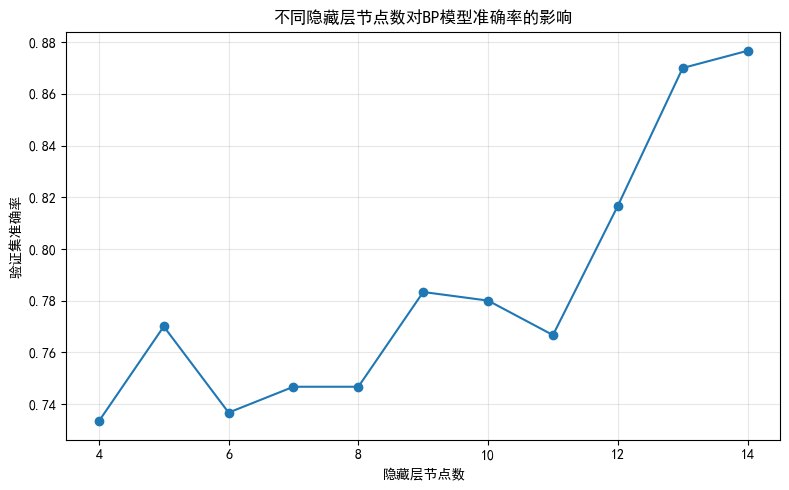

In [43]:
# Cell 16：不同隐藏层节点数对模型准确率的影响图

plt.figure(figsize=(8, 5))
plt.plot(
    hidden_result_df["隐藏层节点数"],
    hidden_result_df["验证集准确率"],
    marker="o"
)

plt.xlabel("隐藏层节点数")
plt.ylabel("验证集准确率")
plt.title("不同隐藏层节点数对BP模型准确率的影响")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUT_DIR / "01_不同隐藏层节点数准确率.png", dpi=300, bbox_inches="tight")
plt.show()

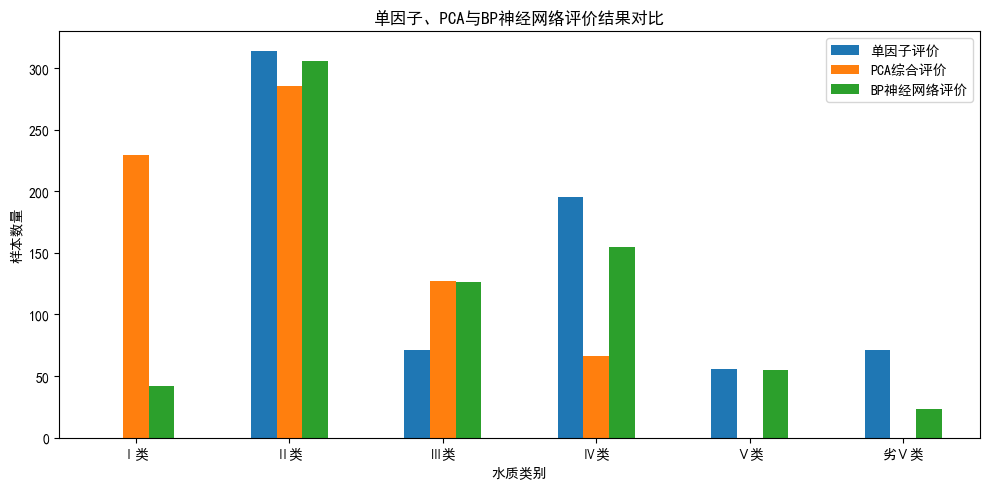

In [46]:
# Cell 17：三种评价方法类别分布对比图

method_compare.plot(kind="bar", figsize=(10, 5))

plt.xlabel("水质类别")
plt.ylabel("样本数量")
plt.title("单因子、PCA与BP神经网络评价结果对比")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(OUT_DIR / "02_三种方法类别分布对比.png", dpi=300, bbox_inches="tight")
plt.show()

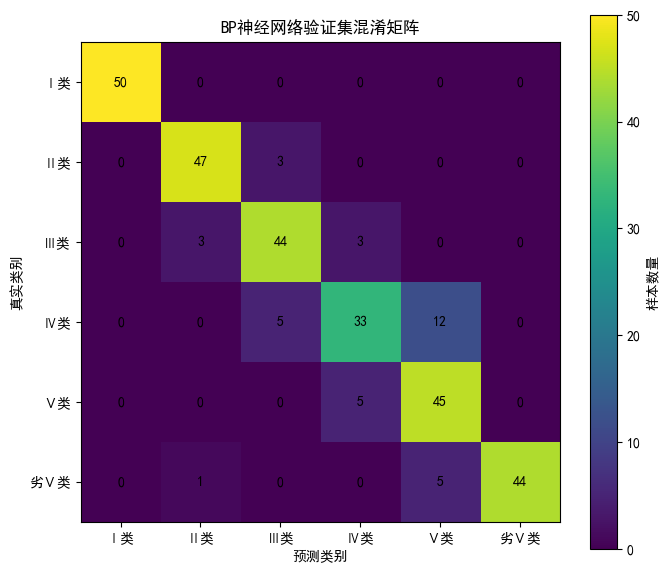

In [47]:
# Cell 18：BP验证集混淆矩阵图

plt.figure(figsize=(7, 6))
plt.imshow(cm, interpolation="nearest")
plt.title("BP神经网络验证集混淆矩阵")
plt.xlabel("预测类别")
plt.ylabel("真实类别")

plt.xticks(range(6), CLASS_ORDER)
plt.yticks(range(6), CLASS_ORDER)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar(label="样本数量")
plt.tight_layout()
plt.savefig(OUT_DIR / "03_BP验证集混淆矩阵.png", dpi=300, bbox_inches="tight")
plt.show()